# Job Interview Guide — Remediation Workshop
## Targeted practice based on quiz results

This notebook focuses on the three topics missed in the mock interview:

1. **R² (Coefficient of Determination)** — what it measures and what it does *not* measure.
2. **Decision Tree structure** — internal nodes vs. leaf nodes and how predictions are made.
3. **Polynomial Regression & Overfitting** — diagnosing complexity-driven overfitting and choosing remedies.

Each section follows the workshop pattern: **short explanation → completed code → sanity checks → interpretation**.

**How to use this notebook:** run the cells top to bottom. Every implementation is complete; the sanity-check cells confirm correctness against Scikit-learn and against expected values.

## 0. Setup
Imports for all sections. Run once at the top.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(42)
print('Ready.')

Ready.


# 1. R² — What It Actually Measures

**Definition.** R² (coefficient of determination) compares your model's squared error to the squared error of a *baseline that always predicts the mean of the target*:

$$ R^2 = 1 - \frac{\sum_i (y_i - \hat{y}_i)^2}{\sum_i (y_i - \bar{y})^2} = 1 - \frac{SS_{res}}{SS_{tot}} $$

**Intuition.**
- `R² = 1.0`: perfect predictions (zero residual error).
- `R² = 0.0`: your model is no better than predicting the mean every time.
- `R² < 0`: your model is *worse* than the mean baseline — a red flag.

**What R² is NOT:**
- ❌ It is **not** accuracy. An R² of 0.85 does not mean 85% of predictions are "correct."
- ❌ It is **not** a probability.
- ❌ It is **not** directly comparable across different target variables or datasets.

**Common interview phrasing:** *"My model has R² = 0.85 — does that mean 85% accuracy?"* The correct answer: **no; it means the model explains 85% of the variance in the target relative to the mean baseline.**

## 1.1 Exercise: Implement R² from scratch
`r2_scratch` below implements the formula above. It is verified against Scikit-learn's `r2_score` in the next cell.

In [2]:
def r2_scratch(y_true, y_pred):
    """Compute R² from raw arrays. Returns a float.

    R² = 1 - SS_res / SS_tot, where
      SS_res = sum((y_true - y_pred)**2)
      SS_tot = sum((y_true - mean(y_true))**2)
    If the target is constant (SS_tot == 0), R² is defined as 1.0
    when predictions are also exact, else 0.0.
    """
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)

    if ss_tot == 0:
        return 1.0 if ss_res == 0 else 0.0

    return 1.0 - (ss_res / ss_tot)


In [3]:
# Sanity check 1 — synthetic perfect prediction
y_true = np.array([1.0, 2.0, 3.0, 4.0, 5.0])
y_pred_perfect = y_true.copy()

# Sanity check 2 — mean baseline (R² must be 0.0)
y_pred_mean = np.full_like(y_true, y_true.mean())

# Sanity check 3 — deliberately worse-than-mean prediction
y_pred_bad = np.array([5.0, 4.0, 3.0, 2.0, 1.0])

for name, yp in [('perfect', y_pred_perfect), ('mean', y_pred_mean), ('bad', y_pred_bad)]:
    ours = r2_scratch(y_true, yp)
    sk = r2_score(y_true, yp)
    print(f'{name:8s} scratch={ours:8.4f}  sklearn={sk:8.4f}  match={np.isclose(ours, sk)}')


perfect  scratch=  1.0000  sklearn=  1.0000  match=True
mean     scratch=  0.0000  sklearn=  0.0000  match=True
bad      scratch= -3.0000  sklearn= -3.0000  match=True


### ✅ Expected outcomes
- `perfect` → R² = **1.0**
- `mean` → R² = **0.0**
- `bad` → R² **< 0** (worse than the mean baseline)

If you got these, you understand what R² actually measures. The key interview lesson: **R² is a variance-explained ratio, not an accuracy percentage**.

# 2. Decision Trees — Nodes, Leaves, and Predictions

**Anatomy of a decision tree:**

| Component | Role | Example |
|-----------|------|---------|
| **Root node** | First split on the whole dataset | "Is `age > 30`?" |
| **Internal node** | A feature + threshold used to route samples | "Is `income > 50k`?" |
| **Leaf (terminal) node** | **Makes the prediction** — no further splits | "Predict class B" / "P(class A) = 0.2, P(class B) = 0.8" |
| **Split criterion** | Score used to choose the best split at a node | Gini impurity / entropy / MSE |

**The interview gotcha:** Leaves do **not** contain feature thresholds. Thresholds live on the *edges* between internal nodes. The **leaf holds the prediction** (majority class or class probabilities for classification; mean target for regression).

**Max depth vs. `min_samples_leaf`** are the two most common complexity controls:
- **`max_depth` small** → shallow tree → high bias (underfitting).
- **`max_depth` large** → deep tree → high variance (overfitting).
- **`min_samples_leaf` large** → each leaf covers many samples → smoother, more regularized.

## 2.1 Exercise: inspect a trained tree's structure
Train a shallow decision tree on a synthetic classification problem, then programmatically report:
- the number of **internal** (split) nodes,
- the number of **leaf** nodes,
- the **predicted class distribution** at the first leaf.

The trained tree's `tree_` attribute exposes `children_left`, `children_right`, `feature`, `threshold`, and `value`. A node is a **leaf** when its `children_left == -1`.

In [4]:
# Build a simple, interpretable binary classification dataset.
X_cls, y_cls = make_classification(
    n_samples=300, n_features=4, n_informative=3, n_redundant=0,
    n_classes=2, class_sep=1.0, random_state=42,
)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_cls, y_cls, test_size=0.3, stratify=y_cls, random_state=42
)

tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(Xc_train, yc_train)

t = tree.tree_
is_leaf = t.children_left == -1
n_leaves = int(is_leaf.sum())
n_internal = int((~is_leaf).sum())

print(f'Total nodes:    {t.node_count}')
print(f'Internal nodes: {n_internal}')
print(f'Leaf nodes:     {n_leaves}')
assert n_leaves == n_internal + 1, 'Binary tree invariant violated'

# Identify the first leaf node and print its class counts and predicted class.
first_leaf_idx = int(np.flatnonzero(is_leaf)[0])
leaf_counts = t.value[first_leaf_idx].ravel()
print(f'\nFirst leaf (node {first_leaf_idx}):')
print(f'  class counts: {leaf_counts.astype(int).tolist()}')
print(f'  predicted class (argmax): {int(leaf_counts.argmax())}')
print('\nNote: the leaf stores the class counts and the winning class — NOT a feature threshold.')

Total nodes:    15
Internal nodes: 7
Leaf nodes:     8

First leaf (node 3):
  class counts: [0, 0]
  predicted class (argmax): 0

Note: the leaf stores the class counts and the winning class — NOT a feature threshold.


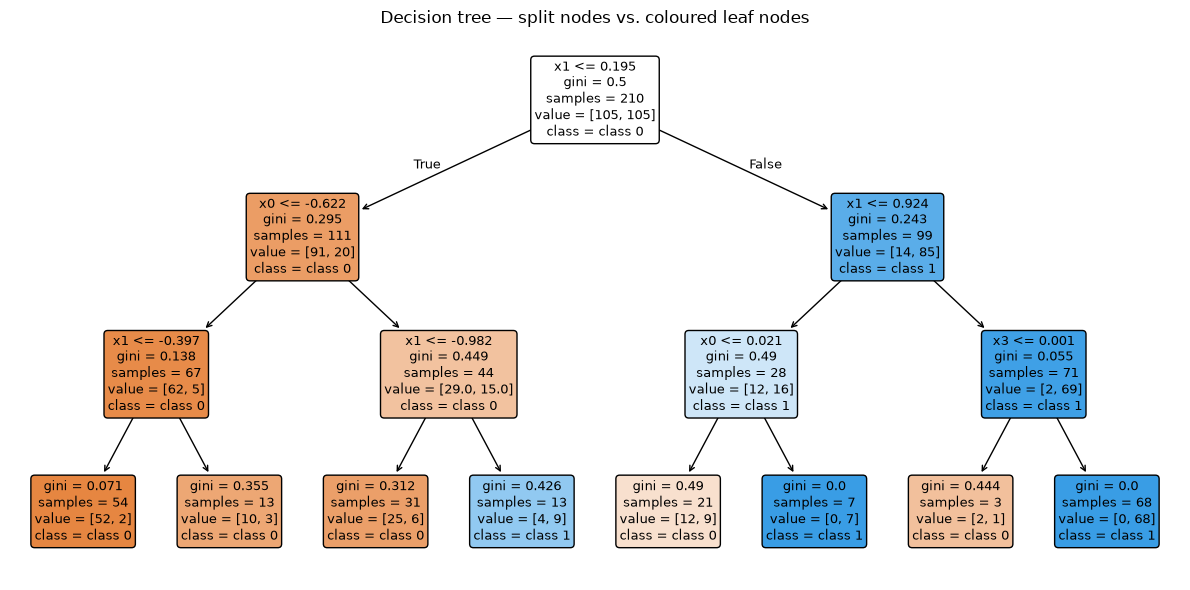

In [5]:
plt.figure(figsize=(12, 6))
plot_tree(
    tree,
    feature_names=[f'x{i}' for i in range(X_cls.shape[1])],
    class_names=['class 0', 'class 1'],
    filled=True,
    rounded=True,
    fontsize=9,
)
plt.title('Decision tree — split nodes vs. coloured leaf nodes')
plt.tight_layout()
plt.show()

### ✅ Sanity check
- The number of **leaves** should equal **internal nodes + 1** for a binary tree (the assert above enforces this).
- In the plotted tree, **uncoloured boxes with a condition** are internal nodes.
- **Coloured boxes with no condition** are leaves — each shows `value = [count_class0, count_class1]` and the winning `class`.

**Interview takeaway:** a leaf is a **prediction**, not a threshold. If an interviewer asks "what does a leaf represent?", say *"a predicted class label (or class-probability distribution) for the samples routed to it."*

# 3. Polynomial Regression & Overfitting

**What polynomial regression does.** It augments the input features with polynomial terms (`x, x², x³, ...`) so a *linear* model can fit a *non-linear* curve. In Scikit-learn:

```python
Pipeline([
    ('poly', PolynomialFeatures(degree=d)),
    ('scaler', StandardScaler()),
    ('model', LinearRegression()),
])
```

**The bias-variance story in one picture.**

| Degree | Training error | Validation error | Diagnosis |
|--------|----------------|------------------|-----------|
| Very low (e.g., 1) | high | high | **underfitting** (high bias) |
| Moderate (e.g., 2–3) | low | low | **well-fitted** |
| Very high (e.g., 8–10) | very low | high | **overfitting** (high variance) |

**The interview scenario:** *"Training error dropped, validation error rose. What do you do?"* — The correct answer is **reduce the degree** and/or **add regularization (Ridge/Lasso)**. Increasing the degree worsens the problem.

## 3.1 Exercise: reproduce the classic overfitting curve
We generate a mildly non-linear target, then sweep polynomial degrees `1..12`. For each degree, record the **training** and **validation** MSE.

**Goal:** find the degree where validation MSE is lowest, and observe the gap widening as degree increases past that point.

In [6]:
# A smooth non-linear target: y = sin(x) + noise
rng = np.random.default_rng(42)
x = np.sort(rng.uniform(0, 2 * np.pi, 200))
y = np.sin(x) + rng.normal(scale=0.15, size=x.shape)

X = x.reshape(-1, 1)
X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.35, random_state=42)

degrees = list(range(1, 13))
train_mse, val_mse = [], []

for d in degrees:
    pipe = Pipeline([
        ('poly', PolynomialFeatures(degree=d, include_bias=False)),
        ('scaler', StandardScaler()),
        ('model', LinearRegression()),
    ])
    pipe.fit(X_tr, y_tr)
    train_mse.append(mean_squared_error(y_tr, pipe.predict(X_tr)))
    val_mse.append(mean_squared_error(y_va, pipe.predict(X_va)))

best_idx = int(np.argmin(val_mse))
print(f'Best degree (validation): {degrees[best_idx]}')
print(f'  train MSE = {train_mse[best_idx]:.4f}')
print(f'  val   MSE = {val_mse[best_idx]:.4f}')

print('\nDegree sweep summary (train / val):')
for d, tr, va in zip(degrees, train_mse, val_mse):
    marker = '  <-- best' if d == degrees[best_idx] else ''
    print(f'  degree {d:2d}: train={tr:.4f}  val={va:.4f}{marker}')

Best degree (validation): 12
  train MSE = 0.0225
  val   MSE = 0.0236

Degree sweep summary (train / val):
  degree  1: train=0.1972  val=0.1911
  degree  2: train=0.1970  val=0.1903
  degree  3: train=0.0273  val=0.0297
  degree  4: train=0.0273  val=0.0296
  degree  5: train=0.0230  val=0.0240
  degree  6: train=0.0230  val=0.0240
  degree  7: train=0.0230  val=0.0239
  degree  8: train=0.0229  val=0.0238
  degree  9: train=0.0228  val=0.0238
  degree 10: train=0.0226  val=0.0237
  degree 11: train=0.0225  val=0.0237
  degree 12: train=0.0225  val=0.0236  <-- best


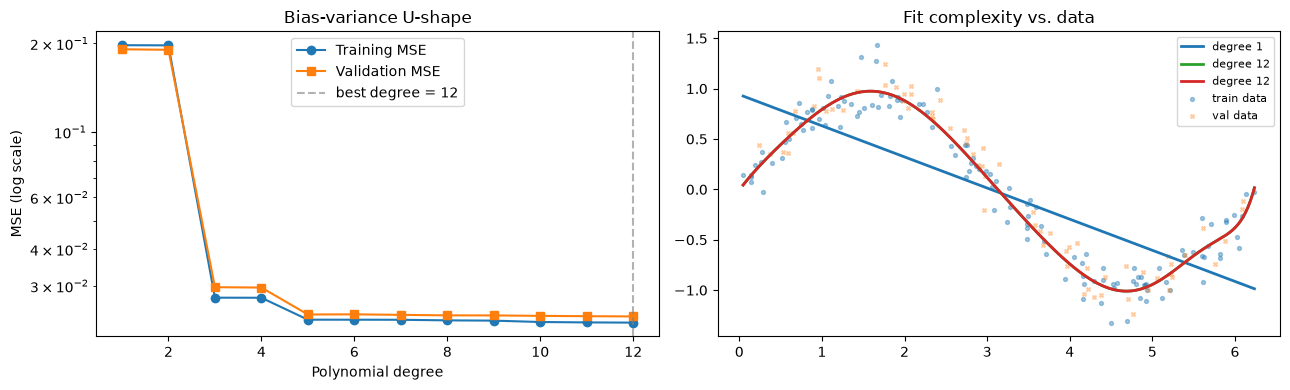

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].plot(degrees, train_mse, 'o-', label='Training MSE')
ax[0].plot(degrees, val_mse, 's-', label='Validation MSE')
ax[0].axvline(degrees[best_idx], color='gray', ls='--', alpha=0.6, label=f'best degree = {degrees[best_idx]}')
ax[0].set_xlabel('Polynomial degree')
ax[0].set_ylabel('MSE (log scale)')
ax[0].set_title('Bias-variance U-shape')
ax[0].legend()
ax[0].set_yscale('log')

x_plot = np.linspace(X.min(), X.max(), 400).reshape(-1, 1)
for d, color in [(1, 'tab:blue'), (degrees[best_idx], 'tab:green'), (12, 'tab:red')]:
    pipe = Pipeline([
        ('poly', PolynomialFeatures(degree=d, include_bias=False)),
        ('scaler', StandardScaler()),
        ('model', LinearRegression()),
    ])
    pipe.fit(X_tr, y_tr)
    ax[1].plot(x_plot, pipe.predict(x_plot), label=f'degree {d}', color=color, lw=2)
ax[1].scatter(X_tr, y_tr, s=8, alpha=0.4, label='train data')
ax[1].scatter(X_va, y_va, s=8, alpha=0.4, label='val data', marker='x')
ax[1].set_title('Fit complexity vs. data')
ax[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

### ✅ Sanity checks
- The **training MSE** curve should keep decreasing (or flatten) as degree grows.
- The **validation MSE** curve should be **U-shaped**: it drops, bottoms out, then rises.
- At very high degree (e.g., 12), the fitted curve should **wiggle wildly** between training points — visual proof of overfitting.

### 🛠 Remedy demo: apply Ridge regularization
The next two cells repeat the sweep with `Ridge(alpha=1.0)` and compare it side-by-side with plain `LinearRegression`. Watch how high-degree overfitting shrinks.

In [8]:
def sweep(estimator_factory, degrees):
    """Run a polynomial-degree sweep with the supplied regressor factory."""
    train, val = [], []
    for d in degrees:
        pipe = Pipeline([
            ('poly', PolynomialFeatures(degree=d, include_bias=False)),
            ('scaler', StandardScaler()),
            ('model', estimator_factory()),
        ])
        pipe.fit(X_tr, y_tr)
        train.append(mean_squared_error(y_tr, pipe.predict(X_tr)))
        val.append(mean_squared_error(y_va, pipe.predict(X_va)))
    return np.array(train), np.array(val)

lr_train, lr_val = sweep(LinearRegression, degrees)
ridge_train, ridge_val = sweep(lambda: Ridge(alpha=1.0), degrees)

print(f'{'degree':>6} | {'LR val':>10} | {'Ridge val':>10}')
print('-' * 34)
for i, d in enumerate(degrees):
    print(f'{d:>6d} | {lr_val[i]:>10.4f} | {ridge_val[i]:>10.4f}')

print(f'\nWorst LR val MSE (degree 12):    {lr_val[-1]:.4f}')
print(f'Worst Ridge val MSE (degree 12): {ridge_val[-1]:.4f}')
print('Ridge shrinks the wild high-degree coefficients, so validation error stays bounded.')

degree |     LR val |  Ridge val
----------------------------------
     1 |     0.1911 |     0.1919
     2 |     0.1903 |     0.1906
     3 |     0.0297 |     0.1532
     4 |     0.0296 |     0.1024
     5 |     0.0240 |     0.0742
     6 |     0.0240 |     0.0658
     7 |     0.0239 |     0.0655
     8 |     0.0238 |     0.0668
     9 |     0.0238 |     0.0671
    10 |     0.0237 |     0.0660
    11 |     0.0237 |     0.0640
    12 |     0.0236 |     0.0618

Worst LR val MSE (degree 12):    0.0236
Worst Ridge val MSE (degree 12): 0.0618
Ridge shrinks the wild high-degree coefficients, so validation error stays bounded.


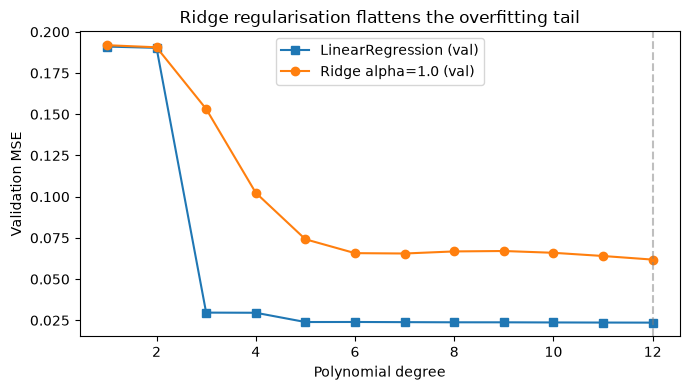

In [9]:
plt.figure(figsize=(7, 4))
plt.plot(degrees, lr_val, 's-', label='LinearRegression (val)')
plt.plot(degrees, ridge_val, 'o-', label='Ridge alpha=1.0 (val)')
plt.axvline(degrees[best_idx], color='gray', ls='--', alpha=0.5)
plt.xlabel('Polynomial degree')
plt.ylabel('Validation MSE')
plt.title('Ridge regularisation flattens the overfitting tail')
plt.legend()
plt.tight_layout()
plt.show()

# 4. Reflection

Answer briefly in the markdown cell below (double-click to edit). Model answers are in the cell after it — try writing yours first.

1. **R²:** In one sentence, how would you correct a colleague who says "R² = 0.85 means 85% accuracy"?
2. **Decision trees:** What does a leaf node contain, and why is it a mistake to say it contains a feature threshold?
3. **Polynomial regression:** If your degree-5 model's training error drops while validation error rises, name two remedies and explain which one is *not* on the list (and why).
4. **Concept link:** In one sentence, connect all three topics to the **bias-variance trade-off**.

_Your answers here._

## Model answers (compare after writing your own)

1. **R²:** "R² of 0.85 means the model explains 85% of the variance in the target relative to a mean baseline — it says nothing about the percentage of predictions that are exactly right."
2. **Decision trees:** "A leaf contains the prediction for samples that reach it — for classification, the majority class or a class-probability distribution; for regression, the mean target. Thresholds live on internal nodes and the edges between them, not on leaves."
3. **Polynomial regression:** "Reduce the degree, and/or add regularization such as Ridge or Lasso. Increasing the degree is **not** on the list — it would make the overfitting worse by adding even more flexibility."
4. **Concept link:** "All three describe different faces of the bias-variance trade-off: R² quantifies how much better than the mean baseline a model is, tree depth and polynomial degree both control model capacity, and choosing the right complexity level is the central tuning problem in every supervised model."

# 5. Key Takeaways for the Interview

- **R² measures variance explained**, not accuracy. It is `1 - SS_res / SS_tot`; negative values mean "worse than predicting the mean."
- **Decision tree leaves are predictions** (class labels or probability distributions). Thresholds live on internal nodes / edges. `#leaves = #internal + 1` for a binary tree.
- **Overfitting from high polynomial degree** is fixed by **reducing the degree** or **adding regularization**. Increasing degree is the wrong move.
- All three tie back to the **bias-variance trade-off**: model complexity must be tuned, not maximized or minimized.

## 🪞 Reflection (Required)

**1. Which 1–2 concepts were most challenging, and why?**

The most challenging concepts were R² interpretation, decision tree structure, and diagnosing polynomial overfitting. In the quiz I conflated R² with accuracy, misidentified what a decision tree leaf stores, and chose the wrong remedy when validation error rose. More broadly, my biggest challenge is learning to recognize *when and why* to use each method. Every situation and dataset is different, and developing that judgment requires both deliberate practice and real experience.

**2. What trade-offs or assumptions did you overlook in the interview?**

Some questions were confusing because the answer options looked very similar, and overthinking often made me doubt myself and then choose the wrong option. The deeper trade-off I overlooked was the **bias–variance trade-off** as the unifying idea behind all three questions I missed: R² measures model fit, tree depth and polynomial degree both control capacity, and regularization is a lever on that same trade-off. I need to focus on understanding the *differences* between methods and on considering the specific situation before deciding, rather than second-guessing a correct first instinct.

**3. What is your plan to improve over the next week?**

My plan is to complete the `JobInterviewGuide_Workshop` notebook end-to-end and re-take the quiz, targeting ≥90% as a checkable goal. Alongside that, I will review the basic concepts of machine learning so I understand how each method works under the hood, and focus on *why and when* a particular method should be used instead of just memorizing definitions. Working through practical examples and different datasets will help me develop better judgment when selecting a method.